# 04 - اكتشاف الحواف والأشكال والنقاط المميزة

**المشروع:** Vision Studio - معالجة الصور والرؤية بالحاسوب  
**المقرر:** معالجة الصور والرؤية بالحاسوب - بكالوريوس ذكاء اصطناعي  
**إشراف:** الدكتورة سمية الشيبة

في هذا الدفتر سنحوّل موضوعات الحواف من المحاضرات إلى وظائف عملية قابلة للنقل لاحقًا إلى تطبيق Android يعمل دون إنترنت.

## أهداف الدفتر

بعد تنفيذ الدفتر ستتمكن من:

1. اكتشاف الحواف باستخدام **Sobel وLaplacian وCanny**.
2. تحسين حدة الصورة باستخدام Laplacian.
3. اكتشاف الخطوط باستخدام **Probabilistic Hough Transform**.
4. اكتشاف الدوائر باستخدام **Hough Circle Transform**.
5. اكتشاف الزوايا والنقاط المميزة باستخدام **Shi-Tomasi**.
6. مقارنة النتائج بصريًا وتغيير المعاملات تفاعليًا.
7. معالجة جميع صور المشروع وحفظ النتائج تلقائيًا في Google Drive.

> ملاحظة مهمة للإنترنت البطيء: الدفتر يعيد استخدام الصور الموجودة في Drive، ولا يرفع أي ملف إلا إذا غيّرت `UPLOAD_NEW_FILES` إلى `True`.

## 1. استيراد المكتبات وربط Google Drive

In [1]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    PROJECT_ROOT = Path(
        '/content/drive/MyDrive/'
        'VisionStudio_Android_ImageProcessing'
    )
except ImportError:
    IN_COLAB = False
    PROJECT_ROOT = Path('VisionStudio_Android_ImageProcessing')

INPUT_DIR = PROJECT_ROOT / '02_Data/Images/Input'
OUTPUT_DIR = (
    PROJECT_ROOT
    / '04_Outputs/Images/04_Edge_Shape_Detection'
)

INPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('Running in Colab:', IN_COLAB)
print('Input directory:', INPUT_DIR)
print('Output directory:', OUTPUT_DIR)

Mounted at /content/drive
Running in Colab: True
Input directory: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/02_Data/Images/Input
Output directory: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/04_Edge_Shape_Detection


## 2. دوال العرض والتحقق

يستخدم OpenCV ترتيب الألوان BGR، بينما يستخدم Matplotlib ترتيب RGB. لذلك تحول دالة `to_rgb` الصورة للعرض فقط، من دون تغيير الصورة الأصلية المستخدمة في المعالجة.

In [2]:
def to_rgb(image):
    if image.ndim == 2:
        return image
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def show_comparison(results, columns=3, figure_width=16):
    items = list(results.items())
    rows = int(np.ceil(len(items) / columns))
    fig, axes = plt.subplots(
        rows, columns,
        figsize=(figure_width, rows * 4.5),
        squeeze=False
    )

    for axis, (title, result) in zip(axes.ravel(), items):
        axis.imshow(
            to_rgb(result),
            cmap='gray' if result.ndim == 2 else None
        )
        axis.set_title(title)
        axis.axis('off')

    for axis in axes.ravel()[len(items):]:
        axis.axis('off')

    plt.tight_layout()
    plt.show()


def valid_odd_kernel(kernel_size, minimum=1):
    kernel_size = max(int(kernel_size), int(minimum))
    if kernel_size % 2 == 0:
        kernel_size += 1
    return kernel_size


def normalize_for_display(image):
    return cv2.normalize(
        image, None, 0, 255, cv2.NORM_MINMAX
    ).astype(np.uint8)

## 3. دوال اكتشاف الحواف وتحسين الحدة

In [3]:
def sobel_edges(image, kernel_size=3):
    k = valid_odd_kernel(kernel_size, minimum=1)
    if k > 7:
        k = 7

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (3, 3), 0)
    sobel_x = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=k)
    sobel_y = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=k)
    magnitude = cv2.magnitude(
        sobel_x.astype(np.float32),
        sobel_y.astype(np.float32)
    )

    return (
        cv2.convertScaleAbs(sobel_x),
        cv2.convertScaleAbs(sobel_y),
        normalize_for_display(magnitude)
    )


def laplacian_edges(image, kernel_size=3):
    k = valid_odd_kernel(kernel_size, minimum=1)
    if k > 7:
        k = 7

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (3, 3), 0)
    laplacian = cv2.Laplacian(blurred, cv2.CV_64F, ksize=k)
    return cv2.convertScaleAbs(laplacian)


def laplacian_sharpen(image, alpha=0.5):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (3, 3), 0)
    laplacian = cv2.Laplacian(blurred, cv2.CV_64F, ksize=3)
    sharpened = gray.astype(np.float64) - float(alpha) * laplacian
    return gray, np.clip(sharpened, 0, 255).astype(np.uint8)


def canny_edges(image, low_threshold=100, high_threshold=200, blur_size=5):
    low = max(0, int(low_threshold))
    high = max(low + 1, int(high_threshold))
    k = valid_odd_kernel(blur_size, minimum=3)

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (k, k), 0)
    return cv2.Canny(blurred, low, high)

## 4. دوال اكتشاف الخطوط والدوائر والزوايا

In [4]:
def detect_lines(
    image, low_threshold=50, high_threshold=128,
    hough_threshold=30, min_line_length=50, max_line_gap=10
):
    edges = canny_edges(
        image, low_threshold, high_threshold, blur_size=5
    )
    lines = cv2.HoughLinesP(
        edges,
        rho=1,
        theta=np.pi / 180,
        threshold=int(hough_threshold),
        minLineLength=int(min_line_length),
        maxLineGap=int(max_line_gap)
    )

    result = image.copy()
    line_count = 0
    if lines is not None:
        line_points = np.asarray(lines).reshape(-1, 4)
        line_count = len(line_points)
        for x1, y1, x2, y2 in line_points:
            cv2.line(result, (x1, y1), (x2, y2), (0, 0, 255), 3)

    return result, line_count, edges


def detect_circles(
    image, dp=1.2, min_distance=40,
    param1=100, param2=30, min_radius=0, max_radius=100
):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blurred = cv2.medianBlur(gray, 5)
    circles = cv2.HoughCircles(
        blurred,
        cv2.HOUGH_GRADIENT,
        dp=float(dp),
        minDist=max(1, float(min_distance)),
        param1=float(param1),
        param2=float(param2),
        minRadius=max(0, int(min_radius)),
        maxRadius=max(0, int(max_radius))
    )

    result = image.copy()
    circle_count = 0
    if circles is not None:
        rounded_circles = np.uint16(
            np.around(np.asarray(circles).reshape(-1, 3))
        )
        circle_count = len(rounded_circles)
        for x, y, radius in rounded_circles:
            cv2.circle(result, (int(x), int(y)), int(radius), (0, 255, 0), 3)
            cv2.circle(result, (int(x), int(y)), 3, (0, 0, 255), -1)

    return result, circle_count


def detect_corners(
    image, max_corners=100, quality_level=0.01, min_distance=10
):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    corners = cv2.goodFeaturesToTrack(
        gray,
        maxCorners=max(1, int(max_corners)),
        qualityLevel=max(0.001, float(quality_level)),
        minDistance=max(1, float(min_distance))
    )

    result = image.copy()
    corner_count = 0
    if corners is not None:
        corner_points = np.int32(
            np.round(np.asarray(corners).reshape(-1, 2))
        )
        corner_count = len(corner_points)
        for x, y in corner_points:
            cv2.circle(result, (int(x), int(y)), 5, (255, 0, 255), -1)

    return result, corner_count

## 5. قراءة صور Drive أو رفع صور جديدة اختياريًا

- اترك `UPLOAD_NEW_FILES = False` في التشغيل المعتاد؛ سيقرأ الدفتر الصور التي رفعتها سابقًا.
- غيّرها إلى `True` فقط عندما تريد إضافة صور جديدة.
- يمكنك وضع اسم صورة محددة لاحقًا في `SELECTED_IMAGE_NAME`.

In [5]:
UPLOAD_NEW_FILES = False
SUPPORTED_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}


def load_images_from_directory(directory):
    images = {}
    for path in sorted(directory.iterdir()):
        if not path.is_file() or path.suffix.lower() not in SUPPORTED_EXTENSIONS:
            continue
        loaded = cv2.imread(str(path), cv2.IMREAD_COLOR)
        if loaded is None:
            print(f'تعذر قراءة الملف: {path.name}')
            continue
        images[path.name] = loaded
    return images


uploaded_images = load_images_from_directory(INPUT_DIR)

if IN_COLAB and UPLOAD_NEW_FILES:
    from google.colab import files

    new_files = files.upload()
    for file_name, file_data in new_files.items():
        image_array = np.frombuffer(file_data, dtype=np.uint8)
        loaded_image = cv2.imdecode(image_array, cv2.IMREAD_COLOR)

        if loaded_image is None:
            print(f'تعذر قراءة الملف: {file_name}')
            continue

        safe_name = Path(file_name).name
        save_path = INPUT_DIR / safe_name
        if not cv2.imwrite(str(save_path), loaded_image):
            raise IOError(f'فشل حفظ الصورة: {save_path}')
        uploaded_images[safe_name] = loaded_image

# صورة اختبار محلية تُنشأ فقط إذا كان مجلد الصور فارغًا.
if not uploaded_images:
    generated = np.full((520, 800, 3), 245, dtype=np.uint8)
    cv2.rectangle(generated, (70, 70), (350, 260), (30, 80, 180), 7)
    cv2.line(generated, (60, 440), (730, 320), (20, 20, 20), 8)
    cv2.line(generated, (410, 90), (740, 250), (180, 40, 30), 7)
    cv2.circle(generated, (540, 350), 95, (30, 150, 40), 7)
    cv2.circle(generated, (700, 110), 50, (150, 30, 150), 6)
    cv2.putText(
        generated, 'VISION', (95, 190),
        cv2.FONT_HERSHEY_SIMPLEX, 1.5, (20, 20, 20), 4, cv2.LINE_AA
    )
    generated_name = 'edge_shape_test.png'
    generated_path = INPUT_DIR / generated_name
    if not cv2.imwrite(str(generated_path), generated):
        raise IOError(f'فشل حفظ صورة الاختبار: {generated_path}')
    uploaded_images[generated_name] = generated
    print('لم توجد صور؛ تم إنشاء صورة اختبار تلقائيًا.')

print(f'عدد الصور المتاحة: {len(uploaded_images)}')
for name, loaded_image in uploaded_images.items():
    height, width = loaded_image.shape[:2]
    print(f'- {name}: {width} x {height}')

عدد الصور المتاحة: 4
- R.jpeg: 736 x 736
- balloons.jpg: 602 x 547
- children.jpeg: 1376 x 774
- coins.jpg: 400 x 390


## 6. اختيار صورة العرض

Selected image: R.jpeg
Shape: (736, 736, 3)
Data type: uint8


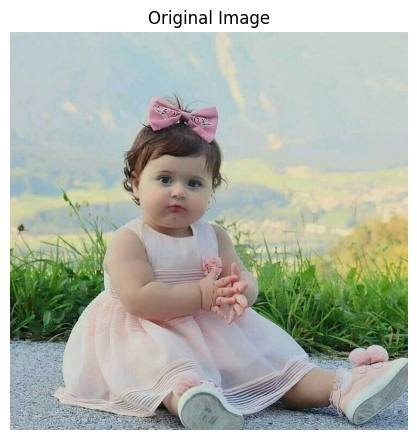

In [6]:
# اتركه فارغًا لاختيار أول صورة، أو اكتب اسم الملف كاملًا بين علامتي الاقتباس.
SELECTED_IMAGE_NAME = ''

if SELECTED_IMAGE_NAME:
    if SELECTED_IMAGE_NAME not in uploaded_images:
        available = ', '.join(uploaded_images.keys())
        raise ValueError(
            f'الصورة غير موجودة. الصور المتاحة: {available}'
        )
    selected_name = SELECTED_IMAGE_NAME
else:
    selected_name = next(iter(uploaded_images))

image = uploaded_images[selected_name]

print('Selected image:', selected_name)
print('Shape:', image.shape)
print('Data type:', image.dtype)
show_comparison({'Original Image': image}, columns=1, figure_width=8)

## 7. مقارنة طرق اكتشاف الحواف

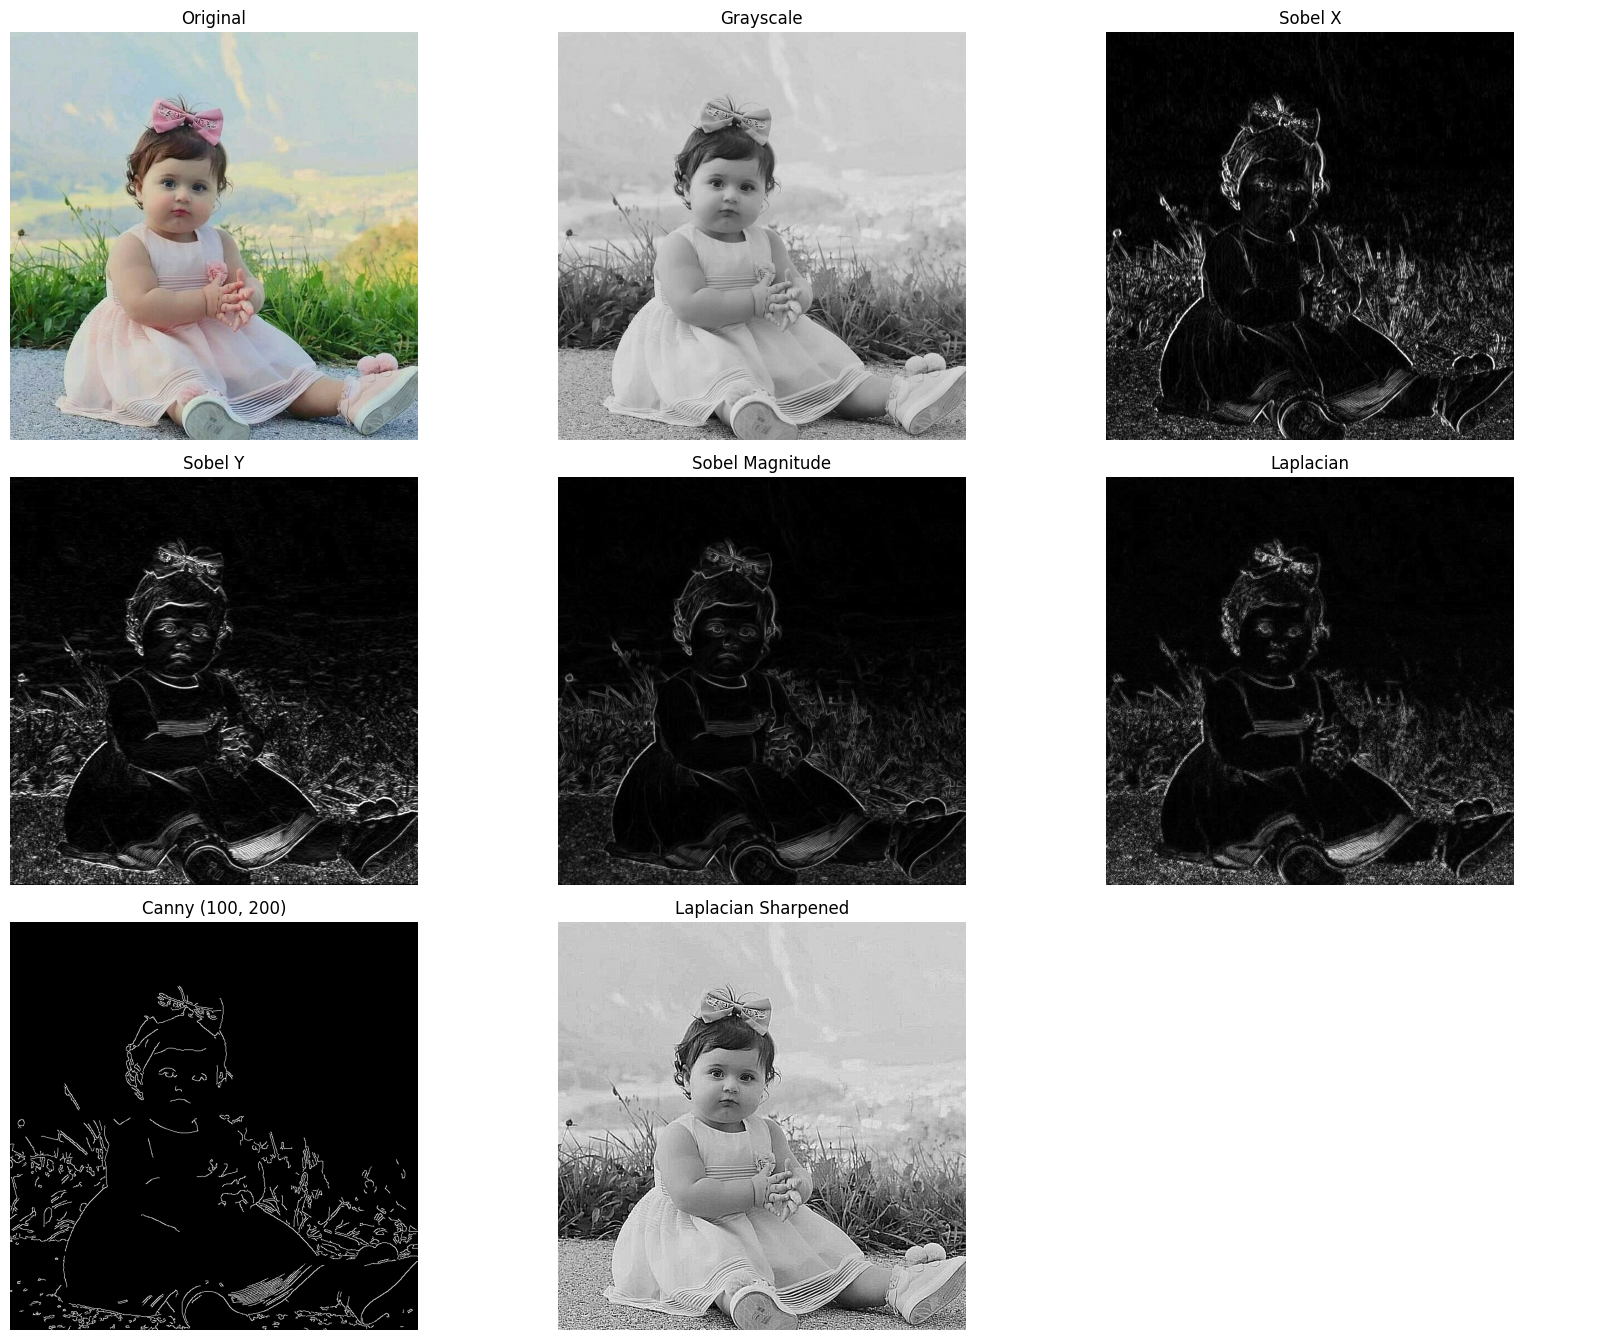

In [7]:
gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
sobel_x, sobel_y, sobel_magnitude = sobel_edges(image, kernel_size=3)
laplacian_result = laplacian_edges(image, kernel_size=3)
canny_result = canny_edges(image, 100, 200, blur_size=5)
_, laplacian_sharpened = laplacian_sharpen(image, alpha=0.5)

show_comparison(
    {
        'Original': image,
        'Grayscale': gray_image,
        'Sobel X': sobel_x,
        'Sobel Y': sobel_y,
        'Sobel Magnitude': sobel_magnitude,
        'Laplacian': laplacian_result,
        'Canny (100, 200)': canny_result,
        'Laplacian Sharpened': laplacian_sharpened
    },
    columns=3,
    figure_width=17
)

### كيف نقرأ المقارنة؟

| الخوارزمية | ما الذي تبرزه؟ | ملاحظة عملية |
|---|---|---|
| Sobel X | التغير الأفقي في شدة الإضاءة، فتظهر الحواف العمودية | يمكن دمجه مع Sobel Y للحصول على مقدار الحافة |
| Sobel Y | التغير العمودي، فتظهر الحواف الأفقية | يتأثر بالضوضاء، لذلك سبقه Gaussian Blur |
| Laplacian | التغير في جميع الاتجاهات بالمشتقة الثانية | سريع لكنه حساس للضوضاء |
| Canny | حواف رفيعة ومتصلة بعد عدة مراحل | يعتمد بقوة على الحدين الأدنى والأعلى |
| Laplacian Sharpening | يعيد تفاصيل الحواف إلى الصورة | القيمة `alpha` تتحكم في قوة الحدة |

## 8. أداة Canny التفاعلية

In [8]:
try:
    import ipywidgets as widgets
    from IPython.display import display
    WIDGETS_AVAILABLE = True
except ImportError:
    WIDGETS_AVAILABLE = False
    print('الأدوات التفاعلية متاحة تلقائيًا داخل Google Colab.')


def interactive_canny(low_threshold=100, high_threshold=200, blur_size=5):
    low = int(low_threshold)
    high = max(low + 1, int(high_threshold))
    k = valid_odd_kernel(blur_size, minimum=3)
    result = canny_edges(image, low, high, k)

    show_comparison(
        {
            'Original': image,
            f'Canny: low={low}, high={high}, blur={k}': result
        },
        columns=2,
        figure_width=12
    )


if WIDGETS_AVAILABLE:
    canny_controls = widgets.interactive(
        interactive_canny,
        low_threshold=widgets.IntSlider(
            value=100, min=0, max=255, step=5, description='Low'
        ),
        high_threshold=widgets.IntSlider(
            value=200, min=1, max=255, step=5, description='High'
        ),
        blur_size=widgets.IntSlider(
            value=5, min=3, max=15, step=2, description='Blur'
        )
    )
    display(canny_controls)
else:
    interactive_canny()

interactive(children=(IntSlider(value=100, description='Low', max=255, step=5), IntSlider(value=200, descripti…

## 9. اكتشاف الخطوط والدوائر والزوايا

Detected lines: 259
Detected circles: 96
Detected corners: 100


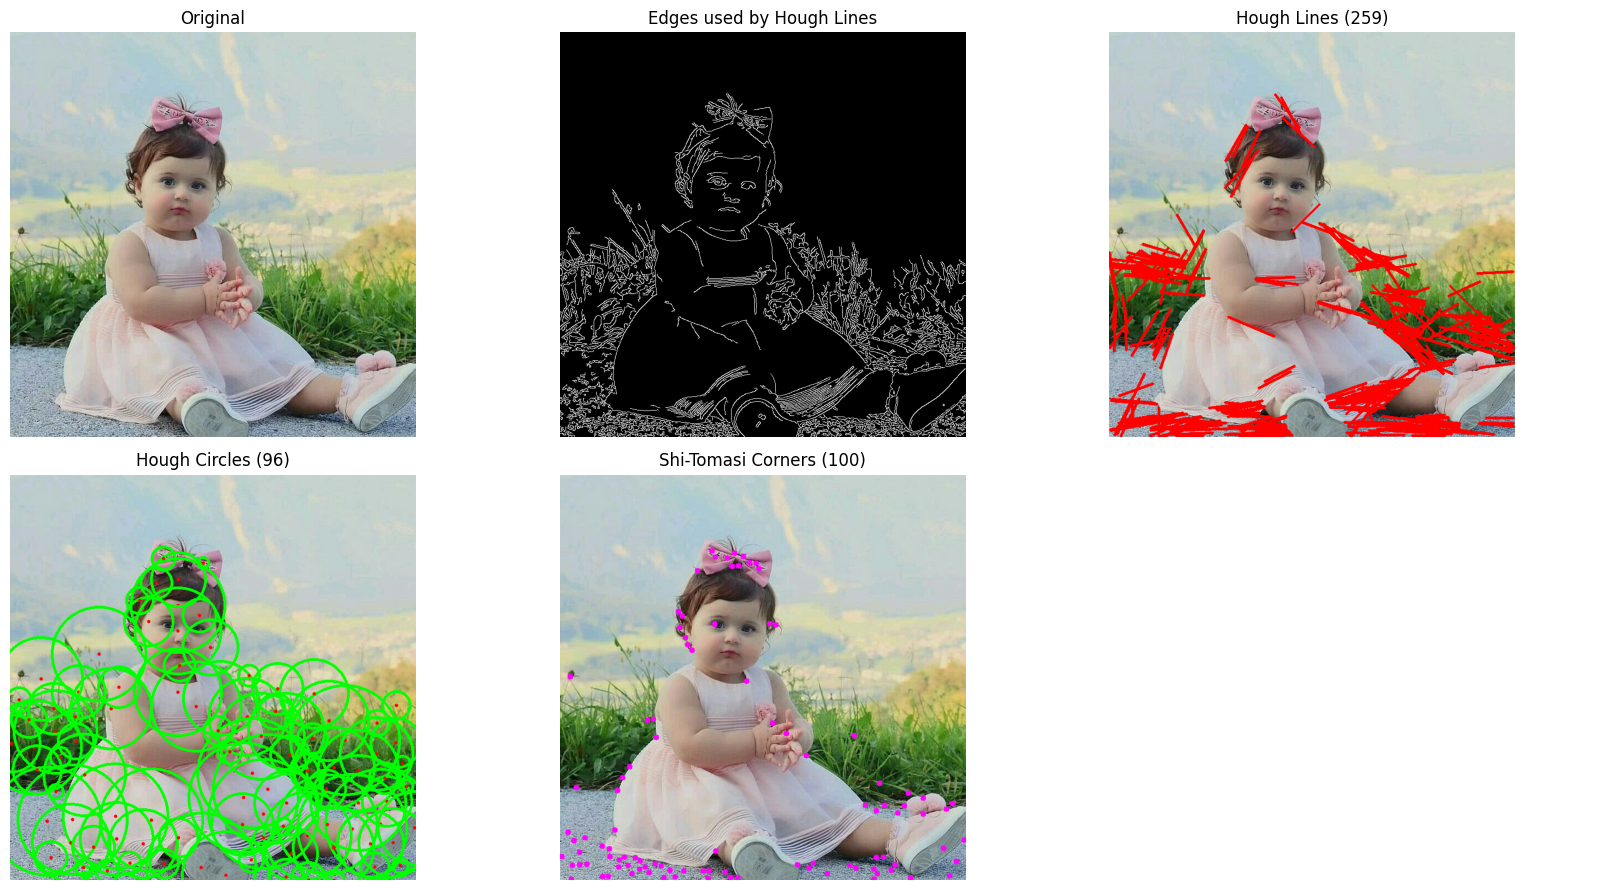

In [9]:
lines_result, line_count, line_edges = detect_lines(image)
circles_result, circle_count = detect_circles(image)
corners_result, corner_count = detect_corners(image)

print('Detected lines:', line_count)
print('Detected circles:', circle_count)
print('Detected corners:', corner_count)

show_comparison(
    {
        'Original': image,
        'Edges used by Hough Lines': line_edges,
        f'Hough Lines ({line_count})': lines_result,
        f'Hough Circles ({circle_count})': circles_result,
        f'Shi-Tomasi Corners ({corner_count})': corners_result
    },
    columns=3,
    figure_width=17
)

### ماذا تعني معاملات Hough؟

- `hough_threshold`: أقل عدد من الأصوات لقبول الخط؛ زيادته تقلل الخطوط المكتشفة.
- `min_line_length`: أقصر طول مقبول للخط.
- `max_line_gap`: أكبر فجوة يسمح بربطها بين قطعتين خطيتين.
- `param2` في Hough Circles: عتبة قبول مركز الدائرة؛ خفضها يكتشف دوائر أكثر، وقد يزيد النتائج الخاطئة.
- `min_radius` و`max_radius`: نطاق نصف قطر الدوائر المتوقع.

## 10. أداة تفاعلية لاكتشاف الأشكال والنقاط

In [10]:
def interactive_detection(
    mode='Lines', sensitivity=30,
    minimum_size=40, maximum_size=120
):
    if mode == 'Lines':
        result, count, _ = detect_lines(
            image,
            hough_threshold=max(1, int(sensitivity)),
            min_line_length=max(1, int(minimum_size)),
            max_line_gap=10
        )
        title = f'Lines detected: {count}'
    elif mode == 'Circles':
        min_radius = max(0, int(minimum_size))
        max_radius = max(min_radius + 1, int(maximum_size))
        result, count = detect_circles(
            image,
            param2=max(1, int(sensitivity)),
            min_radius=min_radius,
            max_radius=max_radius
        )
        title = f'Circles detected: {count}'
    else:
        result, count = detect_corners(
            image,
            max_corners=max(1, int(maximum_size)),
            quality_level=max(0.001, float(sensitivity) / 1000.0),
            min_distance=max(1, int(minimum_size) // 4)
        )
        title = f'Corners detected: {count}'

    show_comparison(
        {'Original': image, title: result},
        columns=2,
        figure_width=12
    )


if WIDGETS_AVAILABLE:
    detection_controls = widgets.interactive(
        interactive_detection,
        mode=widgets.Dropdown(
            options=['Lines', 'Circles', 'Corners'],
            value='Lines',
            description='Mode'
        ),
        sensitivity=widgets.IntSlider(
            value=30, min=5, max=100, step=1,
            description='Threshold'
        ),
        minimum_size=widgets.IntSlider(
            value=40, min=0, max=200, step=5,
            description='Minimum'
        ),
        maximum_size=widgets.IntSlider(
            value=120, min=10, max=300, step=5,
            description='Maximum'
        )
    )
    display(detection_controls)
else:
    interactive_detection()

interactive(children=(Dropdown(description='Mode', options=('Lines', 'Circles', 'Corners'), value='Lines'), In…

## 11. معالجة جميع الصور وحفظ النتائج

ستُنشأ مجلدات منفصلة لكل صورة داخل:

`04_Outputs/Images/04_Edge_Shape_Detection/اسم_الصورة/`

لن تُحذف الصور الأصلية، ولن تُستبدل ملفات الإدخال.

In [11]:
saved_files = []
processing_summary = []

for file_name, source_image in uploaded_images.items():
    stem = Path(file_name).stem
    image_output_dir = OUTPUT_DIR / stem
    image_output_dir.mkdir(parents=True, exist_ok=True)

    source_gray = cv2.cvtColor(source_image, cv2.COLOR_BGR2GRAY)
    source_sobel_x, source_sobel_y, source_sobel_magnitude = sobel_edges(
        source_image, kernel_size=3
    )
    source_laplacian = laplacian_edges(source_image, kernel_size=3)
    source_canny = canny_edges(source_image, 100, 200, blur_size=5)
    _, source_sharpened = laplacian_sharpen(source_image, alpha=0.5)
    source_lines, source_line_count, _ = detect_lines(source_image)
    source_circles, source_circle_count = detect_circles(source_image)
    source_corners, source_corner_count = detect_corners(source_image)

    results = {
        '00_original.png': source_image,
        '01_grayscale.png': source_gray,
        '02_sobel_x.png': source_sobel_x,
        '03_sobel_y.png': source_sobel_y,
        '04_sobel_magnitude.png': source_sobel_magnitude,
        '05_laplacian.png': source_laplacian,
        '06_canny.png': source_canny,
        '07_laplacian_sharpened.png': source_sharpened,
        '08_hough_lines.png': source_lines,
        '09_hough_circles.png': source_circles,
        '10_shi_tomasi_corners.png': source_corners
    }

    for output_name, result_image in results.items():
        output_path = image_output_dir / output_name
        if not cv2.imwrite(str(output_path), result_image):
            raise IOError(f'فشل حفظ الصورة: {output_path}')
        saved_files.append(output_path)

    processing_summary.append({
        'file': file_name,
        'lines': source_line_count,
        'circles': source_circle_count,
        'corners': source_corner_count
    })

print(f'تمت معالجة {len(uploaded_images)} صورة.')
print(f'تم حفظ {len(saved_files)} ملفًا بنجاح.')
print('مجلد النتائج:', OUTPUT_DIR)
print('\nDetection summary:')
for item in processing_summary:
    print(
        f"- {item['file']}: lines={item['lines']}, "
        f"circles={item['circles']}, corners={item['corners']}"
    )

تمت معالجة 4 صورة.
تم حفظ 44 ملفًا بنجاح.
مجلد النتائج: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/04_Edge_Shape_Detection

Detection summary:
- R.jpeg: lines=259, circles=96, corners=100
- balloons.jpg: lines=8, circles=19, corners=100
- children.jpeg: lines=321, circles=220, corners=100
- coins.jpg: lines=98, circles=24, corners=100


## 12. الربط بتطبيق Android

عند بناء نسخة Android باستخدام OpenCV، ستكون المقابلات الأساسية كالتالي:

| Python في Colab | OpenCV Android/Java | الاستخدام داخل التطبيق |
|---|---|---|
| `cv2.Sobel` | `Imgproc.Sobel` | إظهار الحواف الأفقية والعمودية |
| `cv2.Laplacian` | `Imgproc.Laplacian` | الحواف وتحسين الحدة |
| `cv2.Canny` | `Imgproc.Canny` | حواف رفيعة في الصور والفيديو المباشر |
| `cv2.HoughLinesP` | `Imgproc.HoughLinesP` | اكتشاف الخطوط ورسمها فوق الكاميرا |
| `cv2.HoughCircles` | `Imgproc.HoughCircles` | اكتشاف الدوائر |
| `cv2.goodFeaturesToTrack` | `Imgproc.goodFeaturesToTrack` | اكتشاف النقاط المميزة |

في الكاميرا المباشرة سنطبق العملية على كل إطار، لكننا سنقلل دقة إطار المعالجة عند الحاجة للمحافظة على سرعة التطبيق والعمل دون إنترنت.

## 13. أسئلة للمناقشة والتقرير

1. لماذا نستخدم Gaussian Blur قبل Canny أو Laplacian؟
2. ما الفرق بين Sobel وLaplacian من ناحية رتبة المشتقة واتجاه الحواف؟
3. ماذا يحدث عند خفض `low_threshold` و`high_threshold` في Canny كثيرًا؟
4. لماذا يحتاج Hough Lines إلى صورة حواف بدل الصورة الملونة مباشرة؟
5. كيف يؤثر `param2` على عدد الدوائر المكتشفة؟
6. جرّب صورة حقيقية تحتوي على مبانٍ أو طرق، ثم سجّل أفضل معاملات للخطوط.
7. جرّب صورة عملات أو أغطية زجاجات، ثم سجّل أفضل معاملات للدوائر.

**الخلاصة:** هذا الدفتر ينجز مرحلة الحواف والأشكال في نسخة Colab، ويهيئ نفس الوظائف لنقلها لاحقًا إلى واجهة Android والكاميرا المباشرة.